In [1]:
# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving cleaned_dataset.csv to cleaned_dataset.csv


In [4]:
# 3. LOAD CLEANED DATASET

df = pd.read_csv('cleaned_dataset.csv')

df['Date'] = pd.to_datetime(df['Date'])

df = df.sort_values('Date').reset_index(drop=True)

print("Dataset dimensions:", df.shape)
print("\nDate range:")
print(df['Date'].min(), "to", df['Date'].max())

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset dimensions: (720, 8)

Date range:
2023-01-12 00:00:00 to 2025-12-21 00:00:00

Column names:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care', 'Weekday', 'Net_Pressure']

First 5 rows:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Weekday,Net_Pressure
0,2023-01-12,33.0,53.0,34.0,6566,436.0,Thursday,-402.0
1,2023-01-22,32.0,49.0,39.0,7122,227.0,Sunday,-188.0
2,2023-01-23,32.0,50.0,39.0,7280,181.0,Monday,-142.0
3,2023-01-24,47.0,42.0,47.0,7433,175.0,Tuesday,-128.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0,Wednesday,-139.0


In [5]:
# 4. DATA INTEGRITY CHECK

print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate dates:", df['Date'].duplicated().sum())

print("\nData types:")
display(df.dtypes)

print("\nHHS Care summary:")
display(df['Children in HHS Care'].describe())

Missing values:


,0
Date,0
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0
Weekday,0
Net_Pressure,0



Duplicate dates: 0

Data types:


,0
Date,datetime64[ns]
Children apprehended and placed in CBP custody*,float64
Children in CBP custody,float64
Children transferred out of CBP custody,float64
Children in HHS Care,int64
Children discharged from HHS Care,float64
Weekday,object
Net_Pressure,float64



HHS Care summary:


,Children in HHS Care
count,720.000000
mean,6061.275000
std,2833.070109
min,1972.000000
25%,2467.750000
50%,6406.500000
75%,8010.250000
max,11516.000000


In [6]:
# 5. FEATURE ENGINEERING

df_model = df.sort_values('Date').copy()

target = 'Children in HHS Care'

# Lag features
for lag in [1, 7, 14]:
    df_model[f'lag_{lag}'] = df_model[target].shift(lag)

# Rolling averages
df_model['rolling_mean_7'] = (
    df_model[target].shift(1).rolling(7).mean()
)

df_model['rolling_mean_14'] = (
    df_model[target].shift(1).rolling(14).mean()
)

# Rolling variance
df_model['rolling_var_7'] = (
    df_model[target].shift(1).rolling(7).var()
)

df_model['rolling_var_14'] = (
    df_model[target].shift(1).rolling(14).var()
)

# Calendar features
df_model['Month'] = df_model['Date'].dt.month
df_model['Weekday_Num'] = df_model['Date'].dt.dayofweek

# Next recorded observation as target
df_model['Target'] = df_model[target].shift(-1)

# Remove rows with unavailable lag/target values
df_model = df_model.dropna().reset_index(drop=True)

print("Modelling dimensions:", df_model.shape)
print("\nFeatures:")
print(df_model.columns.tolist())

display(df_model.head())

Modelling dimensions: (705, 18)

Features:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care', 'Weekday', 'Net_Pressure', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_var_7', 'rolling_var_14', 'Month', 'Weekday_Num', 'Target']


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Weekday,Net_Pressure,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,rolling_var_7,rolling_var_14,Month,Weekday_Num,Target
0,2023-02-09,124.0,234.0,161.0,7908,353.0,Thursday,-192.0,7915.0,7803.0,6566.0,7808.714286,7558.214286,14128.904762,141066.642857,2,3,7434.0
1,2023-02-12,92.0,203.0,173.0,7434,317.0,Sunday,-144.0,7908.0,7903.0,7122.0,7823.714286,7654.071429,15503.904762,64852.840659,2,6,7483.0
2,2023-02-13,186.0,259.0,172.0,7483,244.0,Monday,-72.0,7434.0,7879.0,7280.0,7756.714286,7676.357143,34531.904762,46266.554945,2,0,7794.0
3,2023-02-14,154.0,225.0,220.0,7794,223.0,Tuesday,-3.0,7483.0,7586.0,7433.0,7700.142857,7690.857143,40792.476190,36831.516484,2,1,7869.0
4,2023-02-15,91.0,199.0,172.0,7869,290.0,Wednesday,-118.0,7794.0,7720.0,7538.0,7729.857143,7716.642857,39059.142857,31819.170330,2,2,7793.0


In [7]:
# 6. CHRONOLOGICAL TRAIN-TEST SPLIT

split = int(len(df_model) * 0.8)

train = df_model.iloc[:split].copy()
test = df_model.iloc[split:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train['Date'].min(), "to", train['Date'].max())

print("\nTesting period:")
print(test['Date'].min(), "to", test['Date'].max())

Training observations: 564
Testing observations: 141

Training period:
2023-02-09 00:00:00 to 2025-05-15 00:00:00

Testing period:
2025-05-18 00:00:00 to 2025-12-18 00:00:00


In [8]:
# 7. SELECT MODEL FEATURES

features = [
    'Children in HHS Care',
    'Children transferred out of CBP custody',
    'Children discharged from HHS Care',
    'Net_Pressure',
    'lag_1',
    'lag_7',
    'lag_14',
    'rolling_mean_7',
    'rolling_mean_14',
    'rolling_var_7',
    'rolling_var_14',
    'Month',
    'Weekday_Num'
]

X_train = train[features]
X_test = test[features]

y_train = train['Target']
y_test = test['Target']

print("Number of model features:", len(features))
print("Training feature dimensions:", X_train.shape)
print("Testing feature dimensions:", X_test.shape)

Number of model features: 13
Training feature dimensions: (564, 13)
Testing feature dimensions: (141, 13)


In [9]:
# 8. TRAIN MACHINE-LEARNING MODELS

# Random Forest
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

rf.fit(X_train, y_train)
rf_predictions = rf.predict(X_test)

# Gradient Boosting
gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)
gb_predictions = gb.predict(X_test)

print("Random Forest training completed.")
print("Gradient Boosting training completed.")

print("\nPrediction dimensions:")
print("Random Forest:", rf_predictions.shape)
print("Gradient Boosting:", gb_predictions.shape)

Random Forest training completed.
Gradient Boosting training completed.

Prediction dimensions:
Random Forest: (141,)
Gradient Boosting: (141,)


In [10]:
# 9. BASELINE MODELS

# Naive persistence: predict next value using current HHS care
naive_predictions = test['Children in HHS Care'].values

# Moving average: use previous 7 observations
moving_avg_predictions = test['rolling_mean_7'].values

print("Naive Persistence predictions:", naive_predictions.shape)
print("Moving Average predictions:", moving_avg_predictions.shape)

Naive Persistence predictions: (141,)
Moving Average predictions: (141,)


In [11]:
# 10. MODEL EVALUATION

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        'Model': name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE (%)': round(mape, 2)
    }


results = [
    evaluate_model('Naive Persistence', y_test, naive_predictions),
    evaluate_model('Moving Average', y_test, moving_avg_predictions),
    evaluate_model('Random Forest', y_test, rf_predictions),
    evaluate_model('Gradient Boosting', y_test, gb_predictions)
]

final_results = pd.DataFrame(results).sort_values('MAE')

display(final_results)

,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,10.30,14.08,0.46
1,Moving Average,41.03,50.11,1.83
2,Random Forest,63.08,84.53,2.93
3,Gradient Boosting,77.76,99.43,3.65


In [12]:
# 11. ARIMA FORECASTING

arima_model = ARIMA(
    train['Children in HHS Care'],
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

arima_predictions = arima_fit.forecast(
    steps=len(test)
)

print("ARIMA model trained successfully.")
print("Prediction count:", len(arima_predictions))

ARIMA model trained successfully.
Prediction count: 141


In [13]:
# 12. EXPONENTIAL SMOOTHING

es_model = ExponentialSmoothing(
    train['Children in HHS Care'],
    trend='add',
    seasonal=None
)

es_fit = es_model.fit(optimized=True)

es_predictions = es_fit.forecast(
    steps=len(test)
)

print("Exponential Smoothing model trained successfully.")
print("Prediction count:", len(es_predictions))

Exponential Smoothing model trained successfully.
Prediction count: 141


In [14]:
# 13. COMPARE ALL SIX MODELS

results = [
    evaluate_model('Naive Persistence', y_test, naive_predictions),
    evaluate_model('Moving Average', y_test, moving_avg_predictions),
    evaluate_model('Random Forest', y_test, rf_predictions),
    evaluate_model('Gradient Boosting', y_test, gb_predictions),
    evaluate_model('ARIMA', y_test, arima_predictions),
    evaluate_model('Exponential Smoothing', y_test, es_predictions)
]

final_results = pd.DataFrame(results).sort_values('MAE')

display(final_results)

,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,10.30,14.08,0.46
1,Moving Average,41.03,50.11,1.83
2,Random Forest,63.08,84.53,2.93
3,Gradient Boosting,77.76,99.43,3.65
4,ARIMA,198.79,242.28,9.37
5,Exponential Smoothing,730.96,809.80,33.26


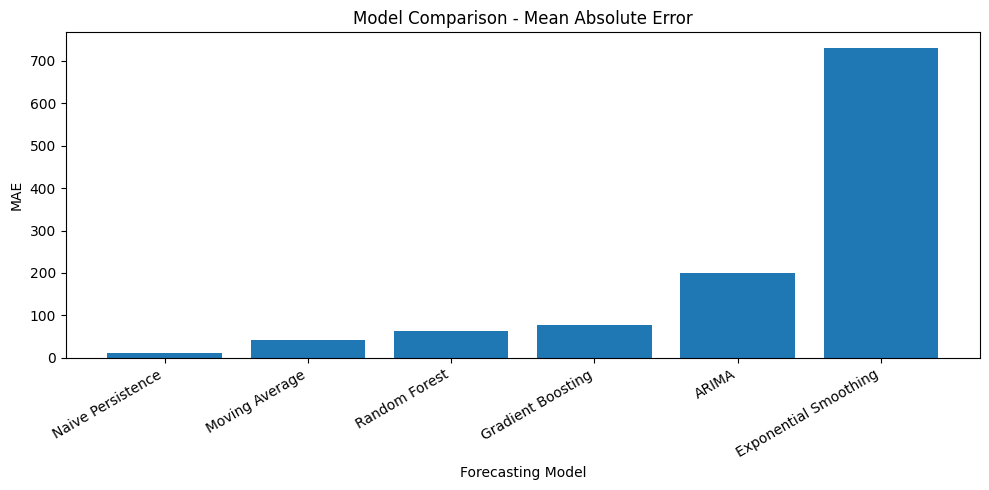

In [15]:
# 14. MODEL COMPARISON CHART

plt.figure(figsize=(10, 5))

plt.bar(
    final_results['Model'],
    final_results['MAE']
)

plt.title('Model Comparison - Mean Absolute Error')
plt.xlabel('Forecasting Model')
plt.ylabel('MAE')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [16]:
# 15. EXPORT MODEL COMPARISON

final_results.to_csv('model_comparison_updated.csv', index=False)

print("Model comparison exported successfully.")

Model comparison exported successfully.


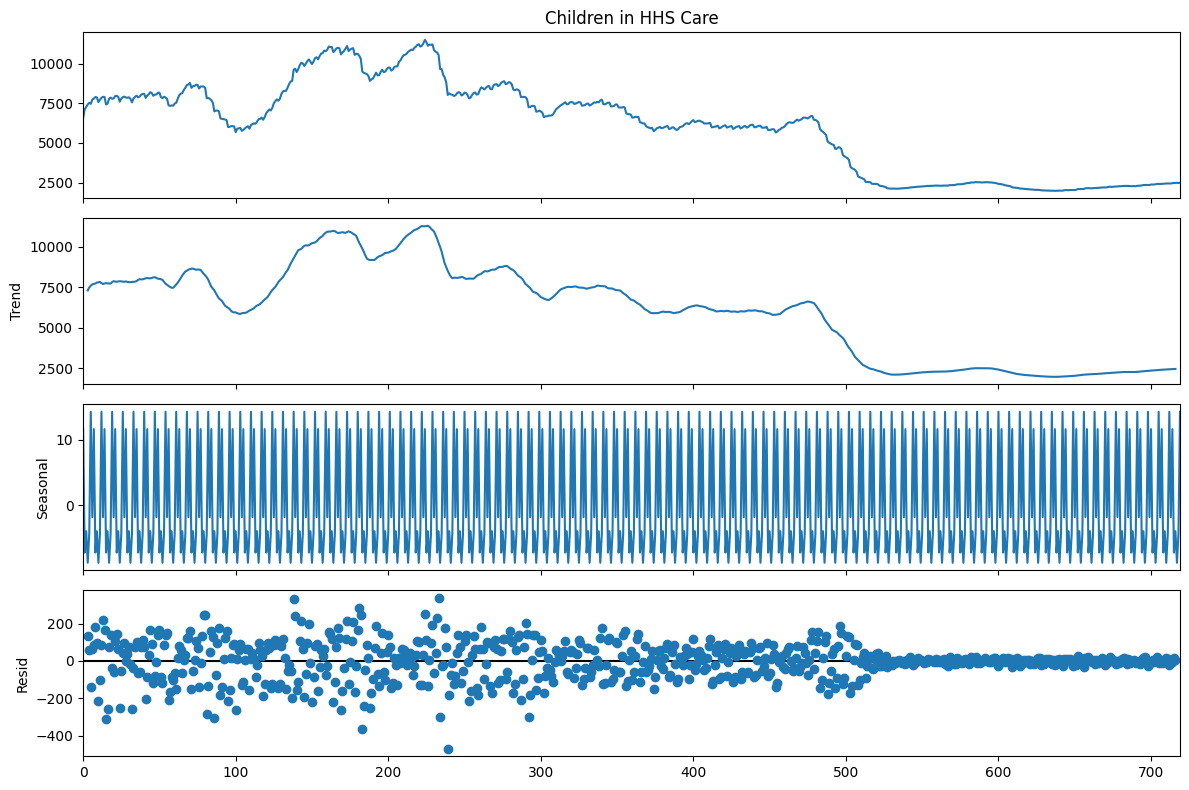

In [17]:
# 16. TIME-SERIES DECOMPOSITION

from statsmodels.tsa.seasonal import seasonal_decompose

hhs_series = df['Children in HHS Care'].reset_index(drop=True)

decomposition = seasonal_decompose(
    hhs_series,
    model='additive',
    period=7
)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

In [18]:
# 17. EXPORT DECOMPOSITION COMPONENTS

decomposition_df = pd.DataFrame({
    'Date': df['Date'],
    'Observed': hhs_series,
    'Trend': decomposition.trend,
    'Seasonal': decomposition.seasonal,
    'Residual': decomposition.resid
})

decomposition_df.to_csv(
    'time_series_decomposition.csv',
    index=False
)

print("Decomposition components exported successfully.")

Decomposition components exported successfully.


In [19]:
# 18. MULTI-HORIZON PERSISTENCE VALIDATION

series = df['Children in HHS Care'].reset_index(drop=True)

validation_results = []

for horizon in [1, 7, 14]:

    actual_values = []
    predicted_values = []

    for i in range(14, len(series) - horizon, 10):

        prediction = series.iloc[i]
        actual = series.iloc[i + horizon]

        predicted_values.append(prediction)
        actual_values.append(actual)

    mae = mean_absolute_error(actual_values, predicted_values)
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))
    mape = np.mean(
        np.abs(
            (np.array(actual_values) - np.array(predicted_values))
            / np.array(actual_values)
        )
    ) * 100

    validation_results.append({
        'Horizon': horizon,
        'Observations': len(actual_values),
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE (%)': round(mape, 2)
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)


,Horizon,Observations,MAE,RMSE,MAPE (%)
0,1,71,75.35,122.16,1.11
1,7,70,321.81,467.02,5.10
2,14,70,585.84,864.20,9.87


In [20]:
# 19. EXPORT MULTI-HORIZON VALIDATION

validation_df.to_csv(
    'multi_horizon_validation.csv',
    index=False
)

print("Multi-horizon validation exported successfully.")

Multi-horizon validation exported successfully.


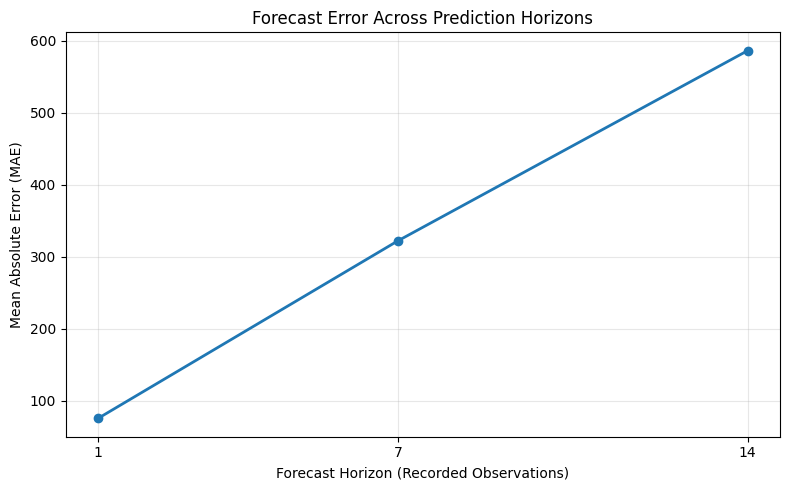

In [21]:
# 20. MULTI-HORIZON ERROR VISUALIZATION

plt.figure(figsize=(8, 5))

plt.plot(
    validation_df['Horizon'],
    validation_df['MAE'],
    marker='o',
    linewidth=2
)

plt.title('Forecast Error Across Prediction Horizons')
plt.xlabel('Forecast Horizon (Recorded Observations)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.xticks([1, 7, 14])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# 21. FUTURE HHS CARE FORECAST

latest_hhs = df['Children in HHS Care'].iloc[-1]
latest_date = df['Date'].iloc[-1]

forecast_horizons = [1, 7, 14]

future_forecast = pd.DataFrame({
    'Forecast_Horizon': forecast_horizons,
    'Forecast_HHS_Care': [latest_hhs] * len(forecast_horizons)
})

print("Latest observation date:", latest_date.date())
print("Latest HHS care population:", latest_hhs)

display(future_forecast)

Latest observation date: 2025-12-21
Latest HHS care population: 2484


,Forecast_Horizon,Forecast_HHS_Care
0,1,2484
1,7,2484
2,14,2484


In [23]:
# 22. ILLUSTRATIVE FORECAST ERROR RANGES

forecast_uncertainty = validation_df[
    ['Horizon', 'MAE']
].copy()

forecast_uncertainty['Forecast'] = latest_hhs

forecast_uncertainty['Lower_Estimate'] = (
    latest_hhs - forecast_uncertainty['MAE']
).clip(lower=0)

forecast_uncertainty['Upper_Estimate'] = (
    latest_hhs + forecast_uncertainty['MAE']
)

forecast_uncertainty = forecast_uncertainty.rename(
    columns={'Horizon': 'Forecast_Horizon'}
)

display(forecast_uncertainty)

,Forecast_Horizon,MAE,Forecast,Lower_Estimate,Upper_Estimate
0,1,75.35,2484,2408.65,2559.35
1,7,321.81,2484,2162.19,2805.81
2,14,585.84,2484,1898.16,3069.84


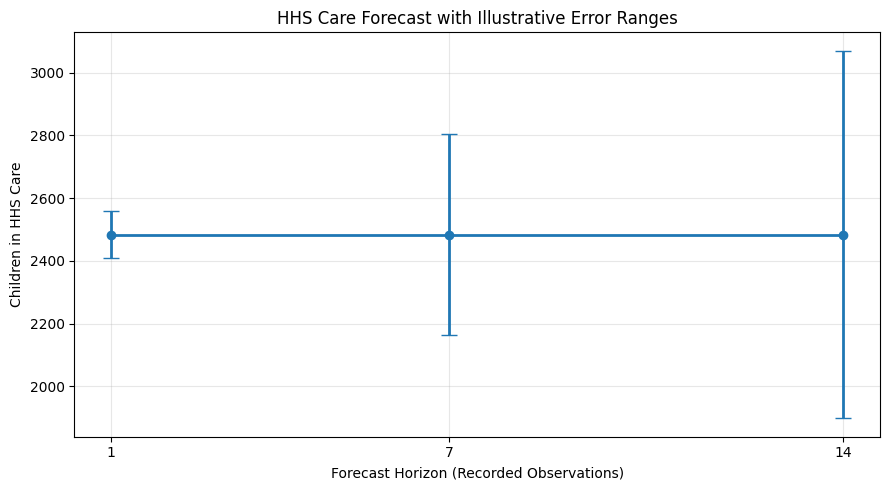

In [24]:
# 23. FORECAST UNCERTAINTY VISUALIZATION

plt.figure(figsize=(9, 5))

plt.errorbar(
    forecast_uncertainty['Forecast_Horizon'],
    forecast_uncertainty['Forecast'],
    yerr=[
        forecast_uncertainty['Forecast'] - forecast_uncertainty['Lower_Estimate'],
        forecast_uncertainty['Upper_Estimate'] - forecast_uncertainty['Forecast']
    ],
    fmt='o-',
    capsize=6,
    linewidth=2
)

plt.title('HHS Care Forecast with Illustrative Error Ranges')
plt.xlabel('Forecast Horizon (Recorded Observations)')
plt.ylabel('Children in HHS Care')
plt.xticks([1, 7, 14])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# 24. EXPORT FORECAST OUTPUTS

future_forecast.to_csv(
    'future_hhs_forecast.csv',
    index=False
)

forecast_uncertainty.to_csv(
    'forecast_uncertainty.csv',
    index=False
)

print("Future HHS forecast exported.")
print("Forecast uncertainty data exported.")

Future HHS forecast exported.
Forecast uncertainty data exported.


In [26]:
# 25. FUTURE DISCHARGE DEMAND FORECAST

discharge_target = 'Children discharged from HHS Care'

latest_discharge = df[discharge_target].iloc[-1]
latest_date = df['Date'].iloc[-1]

discharge_forecast = pd.DataFrame({
    'Forecast_Horizon': [1, 7, 14],
    'Forecast_Discharge_Demand': [latest_discharge] * 3
})

print("Latest observation date:", latest_date.date())
print("Latest recorded discharges:", latest_discharge)

display(discharge_forecast)

Latest observation date: 2025-12-21
Latest recorded discharges: 14.0


,Forecast_Horizon,Forecast_Discharge_Demand
0,1,14.0
1,7,14.0
2,14,14.0


In [27]:
# 26. DISCHARGE FORECAST VALIDATION

discharge_series = df['Children discharged from HHS Care'].reset_index(drop=True)

discharge_validation = []

for horizon in [1, 7, 14]:

    actual_values = []
    predicted_values = []

    for i in range(14, len(discharge_series) - horizon, 10):

        predicted = discharge_series.iloc[i]
        actual = discharge_series.iloc[i + horizon]

        predicted_values.append(predicted)
        actual_values.append(actual)

    mae = mean_absolute_error(actual_values, predicted_values)
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))

    mape = np.mean(
        np.abs(
            (np.array(actual_values) - np.array(predicted_values))
            / np.maximum(np.abs(actual_values), 1)
        )
    ) * 100

    discharge_validation.append({
        'Horizon': horizon,
        'Observations': len(actual_values),
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE (%)': round(mape, 2)
    })

discharge_validation_df = pd.DataFrame(discharge_validation)

display(discharge_validation_df)

,Horizon,Observations,MAE,RMSE,MAPE (%)
0,1,71,39.07,52.16,33.56
1,7,70,58.27,77.96,50.73
2,14,70,41.01,57.25,46.97


In [28]:
# 27. EXPORT DISCHARGE VALIDATION

discharge_validation_df.to_csv(
    'discharge_validation.csv',
    index=False
)

discharge_forecast.to_csv(
    'discharge_forecast.csv',
    index=False
)

print("Discharge validation exported.")
print("Discharge forecast exported.")

Discharge validation exported.
Discharge forecast exported.


In [29]:
# 28. INTAKE AND EXIT IMBALANCE

print("Net Pressure Summary:")

display(df['Net_Pressure'].describe())

print("\nPositive pressure days:",
      (df['Net_Pressure'] > 0).sum())

print("Negative pressure days:",
      (df['Net_Pressure'] < 0).sum())

print("Balanced days:",
      (df['Net_Pressure'] == 0).sum())

Net Pressure Summary:


,Net_Pressure
count,720.000000
mean,-44.738889
std,95.863856
min,-465.000000
25%,-94.250000
50%,-11.500000
75%,5.250000
max,206.000000



Positive pressure days: 238
Negative pressure days: 475
Balanced days: 7


In [30]:
# 29. ROLLING EARLY-WARNING INDICATOR

df['Net_Pressure_7_Obs_Avg'] = (
    df['Net_Pressure']
    .rolling(window=7, min_periods=7)
    .mean()
)

df['Early_Warning'] = np.where(
    df['Net_Pressure_7_Obs_Avg'] > 0,
    'Positive Pressure',
    'Non-Positive Pressure'
)

print("Early-warning indicator created.")

display(
    df[['Date', 'Net_Pressure',
        'Net_Pressure_7_Obs_Avg', 'Early_Warning']].tail(15)
)

print("\nWarning observations:")
print((df['Early_Warning'] == 'Positive Pressure').sum())

Early-warning indicator created.


,Date,Net_Pressure,Net_Pressure_7_Obs_Avg,Early_Warning
705,2025-12-01,-5.0,3.571429,Positive Pressure
706,2025-12-02,-2.0,3.428571,Positive Pressure
707,2025-12-03,1.0,0.571429,Positive Pressure
708,2025-12-04,-6.0,0.285714,Positive Pressure
709,2025-12-07,1.0,0.000000,Non-Positive Pressure
710,2025-12-08,5.0,0.571429,Positive Pressure
711,2025-12-09,-1.0,-1.000000,Non-Positive Pressure
712,2025-12-10,-4.0,-0.857143,Non-Positive Pressure
713,2025-12-11,-1.0,-0.714286,Non-Positive Pressure
714,2025-12-14,-4.0,-1.428571,Non-Positive Pressure



Warning observations:
250


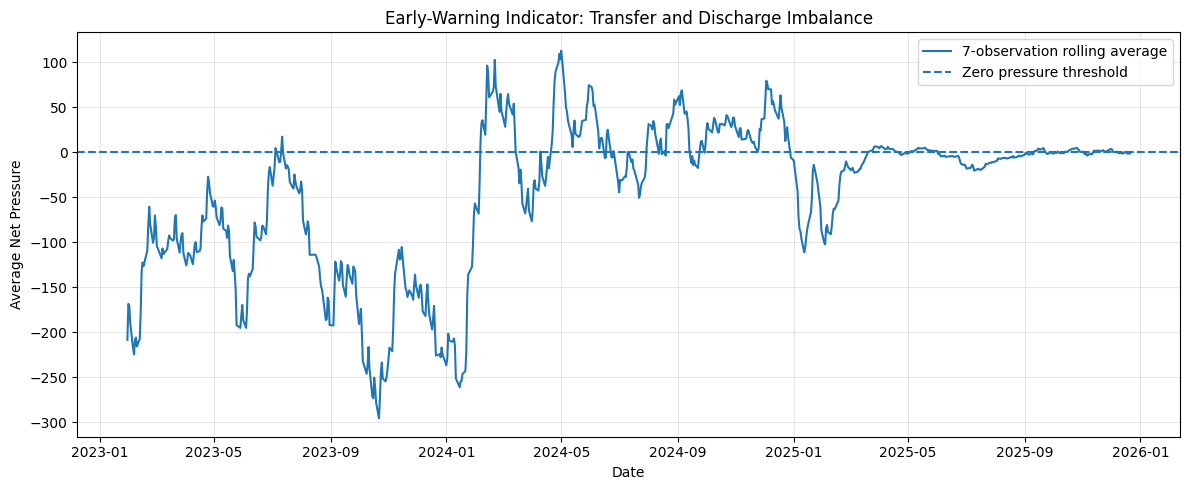

In [31]:
# 30. EARLY-WARNING VISUALIZATION

plt.figure(figsize=(12, 5))

plt.plot(
    df['Date'],
    df['Net_Pressure_7_Obs_Avg'],
    label='7-observation rolling average'
)

plt.axhline(
    y=0,
    linestyle='--',
    label='Zero pressure threshold'
)

plt.title('Early-Warning Indicator: Transfer and Discharge Imbalance')
plt.xlabel('Date')
plt.ylabel('Average Net Pressure')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
# 31. EXPORT EARLY-WARNING DATA

early_warning_output = df[
    [
        'Date',
        'Net_Pressure',
        'Net_Pressure_7_Obs_Avg',
        'Early_Warning'
    ]
].copy()

early_warning_output.to_csv(
    'early_warning_indicators.csv',
    index=False
)

print("Early-warning indicators exported successfully.")

Early-warning indicators exported successfully.


In [33]:
# 32. CAPACITY DATA AVAILABILITY CHECK

capacity_keywords = ['capacity', 'beds', 'occupancy', 'maximum']

capacity_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in capacity_keywords)
]

if capacity_columns:
    print("Capacity-related columns found:")
    print(capacity_columns)
else:
    print("No capacity-related columns found.")
    print("Actual capacity breach probability cannot be calculated.")

No capacity-related columns found.
Actual capacity breach probability cannot be calculated.


In [35]:
# 33. CAPACITY LIMITATION RECORD

capacity_assessment = pd.DataFrame({
    'KPI': [
        'HHS Care Population',
        'Facility Capacity Threshold',
        'Capacity Breach Probability'
    ],
    'Status': [
        'Available',
        'Unavailable in dataset',
        'Cannot be calculated'
    ],
    'Explanation': [
        'Historical HHS care population is available.',
        'No facility capacity or maximum occupancy data provided.',
        'Requires a defined capacity threshold and suitable forecasting uncertainty.'
    ]
})

display(capacity_assessment)

capacity_assessment.to_csv(
    'capacity_limitation_assessment.csv',
    index=False
)

print("Capacity limitation assessment exported.")

,KPI,Status,Explanation
0,HHS Care Population,Available,Historical HHS care population is available.
1,Facility Capacity Threshold,Unavailable in dataset,No facility capacity or maximum occupancy data...
2,Capacity Breach Probability,Cannot be calculated,Requires a defined capacity threshold and suit...


Capacity limitation assessment exported.


In [36]:
# 34. SCENARIO COMPARISON

latest_hhs = df['Children in HHS Care'].iloc[-1]
pressure_std = df['Net_Pressure'].std()

scenario_comparison = pd.DataFrame({
    'Scenario': [
        'Baseline',
        'Higher Pressure',
        'Lower Pressure'
    ],
    'HHS_Care_Estimate': [
        latest_hhs,
        latest_hhs + pressure_std,
        latest_hhs - pressure_std
    ]
})

scenario_comparison['HHS_Care_Estimate'] = (
    scenario_comparison['HHS_Care_Estimate'].round(0).astype(int)
)

display(scenario_comparison)

,Scenario,HHS_Care_Estimate
0,Baseline,2484
1,Higher Pressure,2580
2,Lower Pressure,2388


In [37]:
# 35. EXPORT SCENARIO COMPARISON

scenario_comparison.to_csv(
    'scenario_comparison.csv',
    index=False
)

print("Scenario comparison exported successfully.")

Scenario comparison exported successfully.


In [38]:
# 36. CONSOLIDATED OUTPUT INVENTORY

import os

output_files = [
    'model_comparison_updated.csv',
    'time_series_decomposition.csv',
    'multi_horizon_validation.csv',
    'future_hhs_forecast.csv',
    'forecast_uncertainty.csv',
    'discharge_validation.csv',
    'discharge_forecast.csv',
    'early_warning_indicators.csv',
    'capacity_limitation_assessment.csv',
    'scenario_comparison.csv'
]

output_inventory = pd.DataFrame({
    'File': output_files,
    'Status': [
        'Created' if os.path.exists(file) else 'Missing'
        for file in output_files
    ]
})

display(output_inventory)

print("\nFiles created:",
      (output_inventory['Status'] == 'Created').sum(),
      "of", len(output_files))

,File,Status
0,model_comparison_updated.csv,Created
1,time_series_decomposition.csv,Created
2,multi_horizon_validation.csv,Created
3,future_hhs_forecast.csv,Created
4,forecast_uncertainty.csv,Created
5,discharge_validation.csv,Created
6,discharge_forecast.csv,Created
7,early_warning_indicators.csv,Created
8,capacity_limitation_assessment.csv,Created
9,scenario_comparison.csv,Created



Files created: 10 of 10


In [39]:
# 37. DOWNLOAD ALL MODELLING OUTPUTS

import shutil
from google.colab import files

output_files = [
    'model_comparison_updated.csv',
    'time_series_decomposition.csv',
    'multi_horizon_validation.csv',
    'future_hhs_forecast.csv',
    'forecast_uncertainty.csv',
    'discharge_validation.csv',
    'discharge_forecast.csv',
    'early_warning_indicators.csv',
    'capacity_limitation_assessment.csv',
    'scenario_comparison.csv'
]

shutil.make_archive(
    'uac_modeling_outputs',
    'zip',
    '.',
    ''
)

files.download('uac_modeling_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>